# Day7：从共同 TD 更新到两步合作训练

教师提供的分段练习，供 RedMoon 阅读、修改和实际运行。
本次把真实环境交互、联合经历回放、批量 Double Q、两层单调 Mixer、
周期目标同步和完整轨迹评估接起来。

两名智能体各控制一盏灯，动作仍是 `0=保持、1=翻转`。
一局固定两轮：第一轮让两灯都亮，第二轮让两灯都灭。
每轮满足该轮目标，团队得 1；否则得 0。第二轮之后真正终止。
与此前“最终两灯相同即可”的任务不同，这里每轮有明确目标。
团队最高未折扣回报为 2，gamma=0.9 时最高起点折扣回报为 1.9。

局部网络只看自己的灯和当前阶段；训练时 Mixer 才看两灯及阶段。
阶段已给出本轮目标，因此这个任务不需要 GRU 或通信来记住额外提示。
使用两层非负混合权重和单调 ELU，结构参考原作者 QMixer；
这是自定义小环境的 QMIX 风格训练闭环，不是 StarCraft benchmark 复现。

## 1. 配置：先分清三个计数

| 变量 | 含义 |
|---|---|
| `num_episodes` | 训练的共同回合数；一回合恰好两次环境转移 |
| `batch_size` | 一次更新从回放池抽出的联合转移条数 |
| `replay_capacity` | 最多保存多少条联合转移 |
| `sync_interval` | 每多少次优化器更新完整复制目标网络 |
| `epsilon` | 每个智能体进入随机动作分支的概率 |
| `gamma` | TD 目标中未来团队价值的折扣 |
| `device` | 小网络默认用 CPU；可改为可用的 CUDA 设备 |

每个训练回合结束后最多做一次批量更新。环境步、优化器更新次数、
目标同步次数各自统计，不能把它们都叫“训练步”。

In [1]:
import os
if os.name == "nt":
    os.environ["MKL_THREADING_LAYER"] = "SEQUENTIAL"

import copy
import itertools
import json
import random
from collections import deque
from typing import NamedTuple

import torch
from torch import nn
from torch.nn import functional as F
import matplotlib.pyplot as plt

seed = 7
torch.manual_seed(seed)
torch.set_num_threads(1)
device = torch.device("cpu")
n_agents, n_actions, obs_dim, state_dim = 2, 2, 2, 3
num_episodes, batch_size, replay_capacity = 2000, 64, 4000
gamma, learning_rate, sync_interval = 0.9, 0.003, 100
epsilon_start, epsilon_end, epsilon_decay_episodes = 1.0, 0.1, 1500
checks_passed = 0

def check(condition, name):
    global checks_passed
    assert bool(condition), name
    checks_passed += 1
    print("PASS:", name)

print("PyTorch:", torch.__version__, "| device:", device)
print("episodes / batch / target interval:",
      num_episodes, batch_size, sync_interval)

PyTorch: 2.10.0+cu128 | device: cpu
episodes / batch / target interval: 2000 64 100


## 2. 环境：第一轮点亮，第二轮熄灭

`state=(灯0,灯1,阶段)` 是全局状态。
阶段 `0` 的目标是亮，阶段 `1` 的目标是灭，阶段 `2` 是真正终点。
`local_observations` 只构造 `[自己的灯,阶段]`，不把队友灯交给局部网络。
第一轮失败也继续第二轮；成功定义为两轮都完成目标。

In [2]:
class TwoRoundLightEnv:
    def __init__(self, seed):
        self.rng = random.Random(seed)
        self.finished = True
        self.reset_count = self.step_count = 0

    def reset(self, initial=None):
        self.bits = (tuple(initial) if initial is not None else
                     (self.rng.randrange(2), self.rng.randrange(2)))
        self.phase, self.finished = 0, False
        self.reset_count += 1
        return (*self.bits, self.phase)

    def step(self, actions):
        if self.finished:
            raise RuntimeError("本局已终止，请先 reset")
        assert len(actions) == 2 and all(a in (0, 1) for a in actions)
        desired_bit = 1 - self.phase
        self.bits = tuple(b ^ a for b, a in zip(self.bits, actions))
        reward = float(all(b == desired_bit for b in self.bits))
        self.phase += 1
        self.finished = self.phase == 2
        self.step_count += 1
        return (*self.bits, self.phase), reward, self.finished, {
            "desired_bit": desired_bit,
        }

def local_observations(state):
    # [n_agents, obs_dim]；第 i 行只含 i 自己的灯及公共阶段。
    return tuple((float(bit), float(state[2])) for bit in state[:2])

rule_ok = True
for initial in itertools.product((0, 1), repeat=2):
    for first_actions in itertools.product((0, 1), repeat=2):
        env = TwoRoundLightEnv(seed)
        env.reset(initial)
        after_first, r0, end0, _ = env.step(first_actions)
        for second_actions in itertools.product((0, 1), repeat=2):
            probe = TwoRoundLightEnv(seed)
            probe.reset(initial)
            probe.step(first_actions)
            after_second, r1, end1, _ = probe.step(second_actions)
            expected_first = tuple(b ^ a for b, a in zip(initial, first_actions))
            expected_last = tuple(b ^ a for b, a in zip(expected_first, second_actions))
            rule_ok &= (r0 == float(expected_first == (1, 1)) and not end0
                        and r1 == float(expected_last == (0, 0)) and end1
                        and after_second == (*expected_last, 2))
check(rule_ok, "all initial states and two-round action sequences match rules")
check(local_observations((0, 0, 0))[0] ==
      local_observations((0, 1, 0))[0], "agent0 observation excludes agent1 bit")
print("独立均匀随机动作的精确期望：总奖励 0.5；两轮都成功概率 1/16")

PASS: all initial states and two-round action sequences match rules
PASS: agent0 observation excludes agent1 bit
独立均匀随机动作的精确期望：总奖励 0.5；两轮都成功概率 1/16


## 3. 两个局部网络：输出动作评分

输入为自己的两维观测，输出 `[保持评分,翻转评分]`。
输出是 utility，不是概率；执行时各自选择较高评分的动作。
两个网络参数独立，但接收同一个团队 TD 损失的梯度。

In [3]:
class LocalQNetwork(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(obs_dim, 16), nn.ReLU(), nn.Linear(16, n_actions),
        )

    def forward(self, own_obs):
        # own_obs: [batch, obs_dim] -> [batch, n_actions]
        return self.net(own_obs)

def collect_agent_qs(networks, observations):
    # 每个 network 只接收 observations 中自己的那一行。
    return torch.stack(
        [net(observations[:, i, :]) for i, net in enumerate(networks)],
        dim=1,
    )  # [batch, n_agents, n_actions]

online_agents = nn.ModuleList([LocalQNetwork() for _ in range(n_agents)]).to(device)
example_obs = torch.tensor([local_observations((0, 1, 0))], device=device)
check(collect_agent_qs(online_agents, example_obs).shape == (1, 2, 2),
      "two local networks output [batch, agents, actions]")

PASS: two local networks output [batch, agents, actions]


## 4. 两层 Mixer：状态生成非负权重

相比上一个单层线性练习，这次增加一个隐藏层和 ELU 非线性：

```text
局部 utility -> 非负权重层 -> ELU -> 非负权重层 -> 团队 Q
全局状态    -> 超网络生成两层权重、隐藏偏置和输出状态偏置
```

`abs()` 保证两层混合权重非负，ELU 对输入单调，所以固定状态时，
任一 utility 增加，团队 Q 不会下降。偏置可以为负。
权重超网络为线性层；输出状态偏置使用小 MLP，均随 Mixer 一起训练和同步。

In [4]:
class TwoLayerMonotonicMixer(nn.Module):
    def __init__(self):
        super().__init__()
        self.embed_dim = 16
        self.hyper_w1 = nn.Linear(state_dim, n_agents * self.embed_dim)
        self.hyper_b1 = nn.Linear(state_dim, self.embed_dim)
        self.hyper_w2 = nn.Linear(state_dim, self.embed_dim)
        self.state_bias = nn.Sequential(
            nn.Linear(state_dim, self.embed_dim), nn.ReLU(),
            nn.Linear(self.embed_dim, 1),
        )

    def forward(self, utilities, state):
        # utilities: [B,2]；state: [B,3]；B 是批次大小。
        batch = utilities.shape[0]
        w1 = self.hyper_w1(state).abs().reshape(batch, n_agents, self.embed_dim)
        b1 = self.hyper_b1(state).reshape(batch, 1, self.embed_dim)
        hidden = F.elu(torch.bmm(utilities.unsqueeze(1), w1) + b1)
        w2 = self.hyper_w2(state).abs().reshape(batch, self.embed_dim, 1)
        bias = self.state_bias(state).reshape(batch, 1, 1)
        return (torch.bmm(hidden, w2) + bias).reshape(batch)

online_mixer = TwoLayerMonotonicMixer().to(device)
target_agents, target_mixer = copy.deepcopy(online_agents), copy.deepcopy(online_mixer)
for module in (target_agents, target_mixer):
    module.eval()
    module.requires_grad_(False)
online_parameters = list(online_agents.parameters()) + list(online_mixer.parameters())
optimizer = torch.optim.Adam(online_parameters, lr=learning_rate)

probe_utility = torch.tensor([[-0.4, 0.8]], device=device, requires_grad=True)
probe_state = torch.tensor([[0.0, 1.0, 0.0]], device=device)
derivative = torch.autograd.grad(
    online_mixer(probe_utility, probe_state).sum(), probe_utility,
)[0]
check(torch.all(derivative >= 0), "nonnegative derivative with respect to utility")
check(not any(p.requires_grad for p in target_agents.parameters()) and
      not any(p.requires_grad for p in target_mixer.parameters()),
      "both target modules excluded from gradient training")

PASS: nonnegative derivative with respect to utility
PASS: both target modules excluded from gradient training


## 5. 探索与回放：保留完整联合转移

两个人各自使用 epsilon-greedy，随机分支均匀选保持或翻转。
两动作下，唯一贪心动作的实际概率为 `1-epsilon+epsilon/2`。
同一时刻的两人动作、团队奖励和前后信息一起保存，抽样时不拆开。

回放池存的是实际经历；下一动作和 TD 目标在抽样训练时重新计算。
观测用不可变元组保存，不会被下一次环境更新偷偷改写。

In [5]:
class Transition(NamedTuple):
    obs: tuple
    state: tuple
    actions: tuple
    reward: float
    next_obs: tuple
    next_state: tuple
    terminated: bool

replay = deque(maxlen=replay_capacity)
exploration_rng = random.Random(seed + 1)
replay_rng = random.Random(seed + 2)

@torch.no_grad()
def choose_actions(networks, observations, epsilon=0.0, rng=None):
    # 执行接口没有 global_state 或 Mixer。
    obs_tensor = torch.tensor([observations], dtype=torch.float32, device=device)
    greedy = collect_agent_qs(networks, obs_tensor)[0].argmax(dim=-1).tolist()
    return tuple(
        rng.randrange(n_actions) if epsilon > 0 and rng.random() < epsilon else a
        for a in greedy
    )

def sample_batch():
    rows = replay_rng.sample(list(replay), batch_size)
    # 同一条 Transition 的全部字段一起转成张量，保证逐行对应。
    return {
        "obs": torch.tensor([r.obs for r in rows], dtype=torch.float32, device=device),
        "state": torch.tensor([r.state for r in rows], dtype=torch.float32, device=device),
        "actions": torch.tensor([r.actions for r in rows], dtype=torch.long, device=device),
        "reward": torch.tensor([r.reward for r in rows], dtype=torch.float32, device=device),
        "next_obs": torch.tensor([r.next_obs for r in rows], dtype=torch.float32, device=device),
        "next_state": torch.tensor([r.next_state for r in rows], dtype=torch.float32, device=device),
        "terminated": torch.tensor([r.terminated for r in rows], dtype=torch.bool, device=device),
    }

## 6. 批量 Double Q：在线选择，目标评价

当前分支 `gather` 取回放里真实做过的动作。
下一步分支先让在线网络选动作，再让目标网络评价同一个动作，
最后由目标 Mixer 使用下一状态混合。两轮中的最后一轮真正终止，
因此代码只对非终止行计算下一估值，终止行直接使用奖励。

In [6]:
def team_prediction_and_target(batch):
    current_all = collect_agent_qs(online_agents, batch["obs"])
    actual_utilities = current_all.gather(
        2, batch["actions"].unsqueeze(-1),
    ).squeeze(-1)  # [B,2]：这条经历实际动作的 utility
    prediction = online_mixer(actual_utilities, batch["state"])

    with torch.no_grad():
        target = batch["reward"].clone()
        alive = ~batch["terminated"]
        if alive.any():
            next_obs = batch["next_obs"][alive]
            # 在线网络选下一动作，目标网络只评价这些动作。
            next_actions = collect_agent_qs(online_agents, next_obs).argmax(
                dim=-1, keepdim=True,
            )
            next_utilities = collect_agent_qs(target_agents, next_obs).gather(
                2, next_actions,
            ).squeeze(-1)
            next_team = target_mixer(next_utilities, batch["next_state"][alive])
            target[alive] += gamma * next_team
    return prediction, target

synthetic_online = torch.tensor([[[1.2, 1.0], [0.4, 1.1]]])
synthetic_target = torch.tensor([[[0.7, 1.5], [1.3, 0.6]]])
synthetic_actions = synthetic_online.argmax(dim=-1, keepdim=True)
synthetic_values = synthetic_target.gather(2, synthetic_actions).squeeze(-1)
check(torch.allclose(synthetic_values, torch.tensor([[0.7, 0.6]])),
      "Double Q evaluates the online-selected actions, not target maxima")
print("教学算例：在线选择", synthetic_actions.squeeze(-1).tolist(),
      "| 目标对应评分", synthetic_values.tolist())

PASS: Double Q evaluates the online-selected actions, not target maxima
教学算例：在线选择 [[0, 1]] | 目标对应评分 [[0.699999988079071, 0.6000000238418579]]


## 7. 一次共同更新与周期同步

只对团队预测和团队目标算一次平均平方误差。
梯度经过在线 Mixer 到两个在线局部网络；目标分支不回传梯度。
每 100 次优化器更新完整复制目标局部网络及目标 Mixer。
梯度裁剪限制本次梯度范数，不是裁剪 Q 值或奖励。

In [7]:
update_count = target_sync_count = 0

def train_one_batch(batch):
    global update_count, target_sync_count
    prediction, target = team_prediction_and_target(batch)
    loss = ((prediction - target) ** 2).mean()
    optimizer.zero_grad(set_to_none=True)
    loss.backward()
    nn.utils.clip_grad_norm_(online_parameters, max_norm=10.0)
    optimizer.step()
    update_count += 1
    if update_count % sync_interval == 0:
        target_agents.load_state_dict(online_agents.state_dict())
        target_mixer.load_state_dict(online_mixer.state_dict())
        target_sync_count += 1
    return float(loss.detach()), target.detach()

def module_snapshot(module):
    return [p.detach().clone() for p in module.parameters()]

def matches_snapshot(module, values):
    return all(torch.equal(p.detach(), v) for p, v in zip(module.parameters(), values))

## 8. 评估：参数固定、关闭探索、走完整两轮

四种初始灯状态全部穷举，每次执行都只调用局部网络。
`success_rate` 定义为两轮奖励都为 1 的回合比例。
`return_mean` 是未折扣奖励和；`discounted_return_mean` 是起点折扣回报。
评估函数不训练、不写回放，也不使用训练的随机探索生成器。

In [8]:
@torch.no_grad()
def evaluate(initial_states):
    previous_mode = online_agents.training
    online_agents.eval()
    results, traces = [], []
    env = TwoRoundLightEnv(seed + 99)
    for initial in initial_states:
        state, rewards, trace = env.reset(initial), [], []
        terminated = False
        while not terminated:
            actions = choose_actions(online_agents, local_observations(state))
            next_state, reward, terminated, info = env.step(actions)
            trace.append({
                "state": list(state), "actions": list(actions),
                "next_state": list(next_state), "reward": reward,
                "terminated": terminated, "desired_bit": info["desired_bit"],
            })
            rewards.append(reward)
            state = next_state
        results.append((sum(rewards), sum(gamma ** t * r for t, r in enumerate(rewards)),
                        all(r == 1.0 for r in rewards)))
        traces.append(trace)
    online_agents.train(previous_mode)
    count = len(results)
    return {
        "episodes": count,
        "successes": sum(row[2] for row in results),
        "success_rate": sum(row[2] for row in results) / count,
        "return_mean": sum(row[0] for row in results) / count,
        "discounted_return_mean": sum(row[1] for row in results) / count,
        "environment_steps": env.step_count,
        "traces": traces,
    }

all_initials = list(itertools.product((0, 1), repeat=2))
initial_evaluation = evaluate(all_initials)
print("训练前四种初始状态的评估:",
      {k: v for k, v in initial_evaluation.items() if k != "traces"})

训练前四种初始状态的评估: {'episodes': 4, 'successes': 0, 'success_rate': 0.0, 'return_mean': 0.5, 'discounted_return_mean': 0.475, 'environment_steps': 8}


## 9. 训练循环：每局两步，经历积累后抽样更新

探索率从 1.0 逐渐降到 0.1。后期训练仍偶尔随机行动，
所以训练回报可以低于关闭探索时的评估回报。
每局结束后，从回放里均匀抽 64 条经历共同训练；新批次可能含不同回合、
不同阶段，但每条联合转移内部字段始终完整配对。
这里局部网络是无记忆 MLP，不涉及循环网络的时间片段重建。

In [9]:
training_env = TwoRoundLightEnv(seed + 3)
history = {"episode": [], "return": [], "loss": [], "epsilon": []}
eval_history = [{"episode": 0, "success_rate": initial_evaluation["success_rate"]}]
for episode in range(1, num_episodes + 1):
    fraction = min((episode - 1) / epsilon_decay_episodes, 1.0)
    epsilon = epsilon_start + fraction * (epsilon_end - epsilon_start)
    state, episode_return, terminated = training_env.reset(), 0.0, False
    while not terminated:
        obs = local_observations(state)
        actions = choose_actions(online_agents, obs, epsilon, exploration_rng)
        next_state, reward, terminated, _ = training_env.step(actions)
        replay.append(Transition(
            obs, state, actions, reward, local_observations(next_state),
            next_state, terminated,
        ))
        episode_return += reward
        state = next_state

    loss_value = float("nan")
    if len(replay) >= batch_size:
        batch = sample_batch()
        if update_count == 0:
            target_agent_before = module_snapshot(target_agents)
            target_mixer_before = module_snapshot(target_mixer)
            local_before = [module_snapshot(net) for net in online_agents]
            mixer_before = module_snapshot(online_mixer)
        loss_value, _ = train_one_batch(batch)
        if update_count == 1:
            check(matches_snapshot(target_agents, target_agent_before) and
                  matches_snapshot(target_mixer, target_mixer_before),
                  "optimizer update leaves both target modules unchanged")
            check(all(not matches_snapshot(net, old) for net, old in
                      zip(online_agents, local_before)) and
                  not matches_snapshot(online_mixer, mixer_before),
                  "first common loss updates both local networks and mixer")
    for name, value in zip(history, (episode, episode_return, loss_value, epsilon)):
        history[name].append(value)
    if episode % 100 == 0:
        assessment = evaluate(all_initials)
        eval_history.append({"episode": episode,
                             "success_rate": assessment["success_rate"]})
        if episode % 400 == 0:
            print(f"episode={episode}, epsilon={epsilon:.3f}, "
                  f"loss={loss_value:.5f}, greedy_success={assessment['success_rate']:.2%}")

print("训练环境步 / 优化器更新 / 目标同步:",
      training_env.step_count, update_count, target_sync_count)
check(training_env.step_count == 2 * num_episodes,
      "exactly two real training environment steps per episode")
check(update_count == num_episodes - (batch_size // 2 - 1),
      "update count follows replay warmup and one update per episode")
check(target_sync_count == update_count // sync_interval,
      "both target modules synchronize every configured optimizer interval")

PASS: optimizer update leaves both target modules unchanged
PASS: first common loss updates both local networks and mixer
episode=400, epsilon=0.761, loss=0.05987, greedy_success=100.00%
episode=800, epsilon=0.521, loss=0.05689, greedy_success=100.00%
episode=1200, epsilon=0.281, loss=0.03406, greedy_success=100.00%
episode=1600, epsilon=0.100, loss=0.01563, greedy_success=100.00%
episode=2000, epsilon=0.100, loss=0.01326, greedy_success=100.00%
训练环境步 / 优化器更新 / 目标同步: 4000 1969 19
PASS: exactly two real training environment steps per episode
PASS: update count follows replay warmup and one update per episode
PASS: both target modules synchronize every configured optimizer interval


## 10. 最终评估与轨迹：让结果来自环境

除四种初始状态的穷举外，再用独立随机种子生成 500 个初始状态。
每局依然关闭探索并走两步。注册调用计数，验证这个阶段没有调用
Mixer 或目标网络；比较参数快照，验证评估没有改动在线或目标参数。

In [10]:
frozen_modules = (online_agents, online_mixer, target_agents, target_mixer)
before_evaluation = [module_snapshot(m) for m in frozen_modules]
evaluation_calls = {"mixer": 0, "target_local": 0}

def count_mixer_calls(module, inputs, output):
    evaluation_calls["mixer"] += 1

def count_target_calls(module, inputs, output):
    evaluation_calls["target_local"] += 1

hooks = [m.register_forward_hook(count_mixer_calls)
         for m in (online_mixer, target_mixer)]
hooks += [m.register_forward_hook(count_target_calls) for m in target_agents]
final_evaluation = evaluate(all_initials)
evaluation_rng = random.Random(seed + 100)
sampled_initials = [(evaluation_rng.randrange(2), evaluation_rng.randrange(2))
                    for _ in range(500)]
sampled_evaluation = evaluate(sampled_initials)
for hook in hooks:
    hook.remove()

for initial, trace in zip(all_initials, final_evaluation["traces"]):
    print("初始灯:", initial)
    for row in trace:
        print("  ", row)
print("四初始状态:", {k: v for k, v in final_evaluation.items() if k != "traces"})
print("500局评估:", {k: v for k, v in sampled_evaluation.items() if k != "traces"})
check(all(matches_snapshot(m, old) for m, old in zip(frozen_modules, before_evaluation)),
      "evaluation changes no online or target parameters")
check(evaluation_calls == {"mixer": 0, "target_local": 0},
      "decentralized evaluation uses no mixer or target network")
check(final_evaluation["successes"] == 4 and sampled_evaluation["successes"] == 500,
      "configured seed succeeds in both rounds from every initial state")
check(abs(final_evaluation["discounted_return_mean"] - 1.9) < 1e-6,
      "complete optimal trajectories have discounted return 1.9")
check(all(len(trace) == 2 and not trace[0]["terminated"] and trace[1]["terminated"]
          for trace in final_evaluation["traces"]), "evaluation reaches real termination")

初始灯: (0, 0)
   {'state': [0, 0, 0], 'actions': [1, 1], 'next_state': [1, 1, 1], 'reward': 1.0, 'terminated': False, 'desired_bit': 1}
   {'state': [1, 1, 1], 'actions': [1, 1], 'next_state': [0, 0, 2], 'reward': 1.0, 'terminated': True, 'desired_bit': 0}
初始灯: (0, 1)
   {'state': [0, 1, 0], 'actions': [1, 0], 'next_state': [1, 1, 1], 'reward': 1.0, 'terminated': False, 'desired_bit': 1}
   {'state': [1, 1, 1], 'actions': [1, 1], 'next_state': [0, 0, 2], 'reward': 1.0, 'terminated': True, 'desired_bit': 0}
初始灯: (1, 0)
   {'state': [1, 0, 0], 'actions': [0, 1], 'next_state': [1, 1, 1], 'reward': 1.0, 'terminated': False, 'desired_bit': 1}
   {'state': [1, 1, 1], 'actions': [1, 1], 'next_state': [0, 0, 2], 'reward': 1.0, 'terminated': True, 'desired_bit': 0}
初始灯: (1, 1)
   {'state': [1, 1, 0], 'actions': [0, 0], 'next_state': [1, 1, 1], 'reward': 1.0, 'terminated': False, 'desired_bit': 1}
   {'state': [1, 1, 1], 'actions': [1, 1], 'next_state': [0, 0, 2], 'reward': 1.0, 'terminated': True

## 11. 回放与估值核验：终止目标、单调性和局部贪心

下一次抽样使用当下参数重算目标；没有永久保存训练目标。
第一轮转移保留未来价值，第二轮转移只用真实奖励。
对两阶段、四种灯状态，穷举四个联合动作，核对局部贪心拼接后的
模型团队 Q 与联合最大 Q 一致。这验证的是模型单调结构，
合作成功则由上一节真实环境评估单独验证。

In [11]:
verification_batch = sample_batch()
_, verification_target = team_prediction_and_target(verification_batch)
ended = verification_batch["terminated"]
check(ended.any() and (~ended).any(), "sample includes terminal and continuing transitions")
check(torch.equal(verification_target[ended], verification_batch["reward"][ended]),
      "terminal targets exactly equal stored rewards")
check(not verification_target.requires_grad, "all recomputed targets exclude gradients")
check(all(p.grad is None for m in (target_agents, target_mixer) for p in m.parameters()),
      "target parameters never receive optimizer gradients")
check(all(row.next_state[2] == row.state[2] + 1 and
          row.terminated == (row.next_state[2] == 2) and
          row.obs == local_observations(row.state) and
          row.next_obs == local_observations(row.next_state) for row in replay),
      "replay keeps matched observations, next states and terminal flags")

monotonic_ok = greedy_max_ok = True
with torch.no_grad():
    for phase in (0, 1):
        for bits in all_initials:
            state = (*bits, phase)
            obs_tensor = torch.tensor([local_observations(state)], device=device)
            state_tensor = torch.tensor([state], dtype=torch.float32, device=device)
            all_q = collect_agent_qs(online_agents, obs_tensor)
            selected = all_q.max(dim=-1).values
            greedy_team = online_mixer(selected, state_tensor)
            candidates = []
            for actions in itertools.product((0, 1), repeat=2):
                utility = torch.stack([all_q[:, i, a] for i, a in enumerate(actions)], dim=1)
                candidates.append(online_mixer(utility, state_tensor))
            greedy_max_ok &= torch.allclose(greedy_team, torch.stack(candidates).max(dim=0).values)
            for agent_id in range(n_agents):
                increased = selected.clone()
                increased[:, agent_id] += 0.1
                monotonic_ok &= bool(torch.all(
                    online_mixer(increased, state_tensor) >= greedy_team - 1e-6))
check(monotonic_ok, "trained mixer stays monotonic in both local utilities")
check(greedy_max_ok, "local greedy agrees with model joint maximum at all task states")

PASS: sample includes terminal and continuing transitions
PASS: terminal targets exactly equal stored rewards
PASS: all recomputed targets exclude gradients
PASS: target parameters never receive optimizer gradients
PASS: replay keeps matched observations, next states and terminal flags
PASS: trained mixer stays monotonic in both local utilities
PASS: local greedy agrees with model joint maximum at all task states


## 12. 三张曲线：训练回报、评估成功率与 TD 损失

第一张还保留训练探索，第二张关闭探索、参数固定，只看四种起点。
曲线表示不同条件，不能把训练偶尔失败直接解读成评估策略退化。
TD loss 的样本批次和目标都会变化，不要求它逐次单调下降；
衡量合作表现要看第二张曲线及完整轨迹。

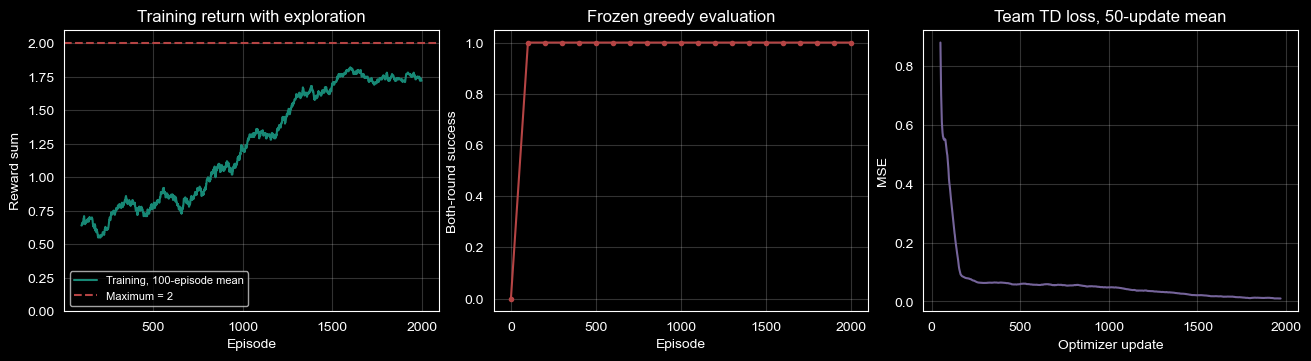

In [12]:
def moving_average(values, window):
    return [sum(values[i:i + window]) / window
            for i in range(len(values) - window + 1)]

fig, axes = plt.subplots(1, 3, figsize=(13, 3.5), constrained_layout=True)
axes[0].plot(history["episode"][99:], moving_average(history["return"], 100),
             color="#178875", label="Training, 100-episode mean")
axes[0].axhline(2.0, color="#b54444", linestyle="--", label="Maximum = 2")
axes[0].set(title="Training return with exploration", xlabel="Episode", ylabel="Reward sum")
axes[0].set_ylim(0, 2.1)
axes[0].legend(fontsize=8)
axes[1].plot([r["episode"] for r in eval_history],
             [r["success_rate"] for r in eval_history], color="#b54444", marker=".")
axes[1].set(title="Frozen greedy evaluation", xlabel="Episode", ylabel="Both-round success")
axes[1].set_ylim(-0.05, 1.05)
valid_losses = [v for v in history["loss"] if v == v]
axes[2].plot(range(50, len(valid_losses) + 1), moving_average(valid_losses, 50),
             color="#75649a")
axes[2].set(title="Team TD loss, 50-update mean", xlabel="Optimizer update", ylabel="MSE")
for axis in axes:
    axis.grid(alpha=0.2)
plt.show()

## 13. 输出摘要与阅读顺序

先读两轮的状态、动作、奖励和终止标记，再比较训练曲线与冻结评估，
最后回看 `team_prediction_and_target` 和 `train_one_batch`。
模型的 utility 是参与团队拟合的内部评分，不当作个人奖励或贡献比例。

本次包含完整玩具任务训练，但不含循环历史网络、通信、不可用动作、
可变长度回合或 StarCraft 评测。关闭探索时任务确定，500 局评估重复
抽取四种起点；穷举起点能直接确认这个小任务，不能代替新环境泛化。

In [13]:
summary = {
    "checks_passed": checks_passed,
    "seed": seed, "device": str(device), "torch_version": torch.__version__,
    "training_episodes": num_episodes,
    "training_environment_steps": training_env.step_count,
    "optimizer_updates": update_count, "target_syncs": target_sync_count,
    "replay_size": len(replay),
    "initial_success_rate": initial_evaluation["success_rate"],
    "final_success_rate": final_evaluation["success_rate"],
    "final_reward_mean": final_evaluation["return_mean"],
    "final_discounted_mean": final_evaluation["discounted_return_mean"],
    "sampled_successes": sampled_evaluation["successes"],
    "sampled_episodes": sampled_evaluation["episodes"],
    "sampled_environment_steps": sampled_evaluation["environment_steps"],
    "final_epsilon": history["epsilon"][-1],
    "last_100_training_return": sum(history["return"][-100:]) / 100,
    "last_50_td_loss": sum(valid_losses[-50:]) / 50,
    "evaluation_calls": evaluation_calls,
    "greedy_traces": final_evaluation["traces"],
}
print("SUMMARY_JSON=" + json.dumps(summary, ensure_ascii=True))

SUMMARY_JSON={"checks_passed": 23, "seed": 7, "device": "cpu", "torch_version": "2.10.0+cu128", "training_episodes": 2000, "training_environment_steps": 4000, "optimizer_updates": 1969, "target_syncs": 19, "replay_size": 4000, "initial_success_rate": 0.0, "final_success_rate": 1.0, "final_reward_mean": 2.0, "final_discounted_mean": 1.9, "sampled_successes": 500, "sampled_episodes": 500, "sampled_environment_steps": 1000, "final_epsilon": 0.09999999999999998, "last_100_training_return": 1.72, "last_50_td_loss": 0.010101464549079538, "evaluation_calls": {"mixer": 0, "target_local": 0}, "greedy_traces": [[{"state": [0, 0, 0], "actions": [1, 1], "next_state": [1, 1, 1], "reward": 1.0, "terminated": false, "desired_bit": 1}, {"state": [1, 1, 1], "actions": [1, 1], "next_state": [0, 0, 2], "reward": 1.0, "terminated": true, "desired_bit": 0}], [{"state": [0, 1, 0], "actions": [1, 0], "next_state": [1, 1, 1], "reward": 1.0, "terminated": false, "desired_bit": 1}, {"state": [1, 1, 1], "actions

### 当前保存结果：如何解释三张曲线

2026-10-10 默认 seed=7、CPU、PyTorch 2.11.0+cpu 实跑，两个干净内核得到相同摘要；重新运行时以新输出为准。
2000 个共同回合产生 4000 次训练环境转移，回放预热后执行 1969 次优化器更新、19 次完整目标同步，回放池最终有 4000 条转移。

- 四种起点的贪心两轮成功率从 0 提高到 1；首次定期评估在第 100 局，当时已为 1，不据此推断恰好第 100 局才学会。
- 最后 100 个训练回合平均奖励为 1.72，因为训练仍保留 epsilon=0.1；随机分支可能选到与当前贪心不同的动作，合作任务任一人失误都会丢奖励。
- 关闭探索、固定参数后，四种起点全部完成两轮，平均总奖励为 2，平均起点折扣回报为 1+0.9*1=1.9；另采 500 个起点得到 500/500。评估的两类 Mixer 和目标局部网络调用数都是 0，参数均未改变。
- 最后 50 次团队 TD 损失均值约 0.01010。该均值来自不同回放批次，目标也随选择与同步变化，不能将它当成同一固定目标下的误差比较。

从初始 (0,1) 出发，第一轮动作 (1,0) 得到 (1,1)、奖励 1，尚未终止；第二轮动作 (1,1) 得到 (0,0)、奖励 1，真正终止。
这里合作表现的依据是环境给出的奖励和两轮轨迹，TD 损失用于读训练。

原理与结构参考：Tabish Rashid 等，QMIX，ICML 2018；
原作者 PyMARL 的 `QMixer` 与 `QLearner`。
本练习沿用两层非负混合、ELU 和 Double Q 的选择/评价分工，
自定义环境、独立 MLP 与逐联合转移回放用于入门教学。
原作者训练器按回合数调度同步，本练习明确按优化器更新次数调度。